In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"D:\datas\airline_flight_delay_data.csv")

In [4]:
df.head()

,flight_id,flight_date,airline,origin,destination,distance_km,scheduled_dep_hour,weather,departure_delay_min,arrival_delay_min,cancelled,seats_available,passengers,avg_ticket_price_inr,fuel_cost_inr,customer_rating
0,FL101634,2024-01-01,Vistara,Ahmedabad,Mumbai,440,20,Clear,26.0,29.0,No,150,116.0,2399.0,41964.0,4.0
1,FL104864,2024-01-01,IndiGo,Chennai,Kolkata,1360,15,Clear,11.0,-16.0,No,186,170.0,6441.0,142392.0,5.0
2,FL102537,2024-01-01,IndiGo,Mumbai,Bengaluru,840,8,Fog,49.0,41.0,No,186,144.0,3592.0,86850.0,5.0
3,FL103364,2024-01-01,SpiceJet,Mumbai,Chennai,1030,10,Fog,68.0,67.0,No,220,218.0,4963.0,114927.0,3.0
4,FL104978,2024-01-01,IndiGo,Ahmedabad,Mumbai,440,18,Fog,NaN,NaN,Yes,186,133.0,1800.0,48287.0,4.0


In [5]:
df.columns

Index(['flight_id', 'flight_date', 'airline', 'origin', 'destination',
       'distance_km', 'scheduled_dep_hour', 'weather', 'departure_delay_min',
       'arrival_delay_min', 'cancelled', 'seats_available', 'passengers',
       'avg_ticket_price_inr', 'fuel_cost_inr', 'customer_rating'],
      dtype='str')

In [6]:
df.columns=df.columns.str.lower()
df.columns=df.columns.str.replace(" ","_")

In [7]:
for col in ['flight_id', 'airline', 'origin','destination', 'weather','cancelled']:
    df[col]=df[col].str.title()

In [8]:
df

,flight_id,flight_date,airline,origin,destination,distance_km,scheduled_dep_hour,weather,departure_delay_min,arrival_delay_min,cancelled,seats_available,passengers,avg_ticket_price_inr,fuel_cost_inr,customer_rating
0,Fl101634,2024-01-01,Vistara,Ahmedabad,Mumbai,440,20,Clear,26.0,29.0,No,150,116.0,2399.0,41964.0,4.0
1,Fl104864,2024-01-01,Indigo,Chennai,Kolkata,1360,15,Clear,11.0,-16.0,No,186,170.0,6441.0,142392.0,5.0
2,Fl102537,2024-01-01,Indigo,Mumbai,Bengaluru,840,8,Fog,49.0,41.0,No,186,144.0,3592.0,86850.0,5.0
3,Fl103364,2024-01-01,Spicejet,Mumbai,Chennai,1030,10,Fog,68.0,67.0,No,220,218.0,4963.0,114927.0,3.0
4,Fl104978,2024-01-01,Indigo,Ahmedabad,Mumbai,440,18,Fog,NaN,NaN,Yes,186,133.0,1800.0,48287.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,Fl101769,2025-12-30,Indigo,Delhi,Bengaluru,1740,8,Fog,-10.0,-9.0,No,150,100.0,5681.0,186143.0,2.0
5021,Fl100128,2025-12-30,Air India,Chennai,Kolkata,1360,13,Clear,42.0,29.0,No,220,185.0,6968.0,140708.0,3.0
5022,Fl104448,2025-12-30,Indigo,Chennai,Kolkata,1360,15,Fog,50.0,51.0,No,186,181.0,6023.0,166314.0,4.0
5023,Fl100245,2025-12-30,Air India,Mumbai,Bengaluru,840,8,Clear,21.0,25.0,No,180,104.0,4315.0,93928.0,4.0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   flight_id             5025 non-null   str    
 1   flight_date           5025 non-null   str    
 2   airline               5025 non-null   str    
 3   origin                5025 non-null   str    
 4   destination           5025 non-null   str    
 5   distance_km           5025 non-null   int64  
 6   scheduled_dep_hour    5025 non-null   int64  
 7   weather               4975 non-null   str    
 8   departure_delay_min   4958 non-null   float64
 9   arrival_delay_min     4958 non-null   float64
 10  cancelled             5025 non-null   str    
 11  seats_available       5025 non-null   int64  
 12  passengers            4872 non-null   float64
 13  avg_ticket_price_inr  5025 non-null   float64
 14  fuel_cost_inr         5025 non-null   float64
 15  customer_rating       4824 non-n

In [10]:
df["flight_date"]=pd.to_datetime(df["flight_date"])

In [11]:
df.dtypes

flight_id                          str
flight_date             datetime64[us]
airline                            str
origin                             str
destination                        str
distance_km                      int64
scheduled_dep_hour               int64
weather                            str
departure_delay_min            float64
arrival_delay_min              float64
cancelled                          str
seats_available                  int64
passengers                     float64
avg_ticket_price_inr           float64
fuel_cost_inr                  float64
customer_rating                float64
dtype: object

In [12]:
df.duplicated().sum()

np.int64(25)

In [13]:
df.drop_duplicates()

,flight_id,flight_date,airline,origin,destination,distance_km,scheduled_dep_hour,weather,departure_delay_min,arrival_delay_min,cancelled,seats_available,passengers,avg_ticket_price_inr,fuel_cost_inr,customer_rating
0,Fl101634,2024-01-01,Vistara,Ahmedabad,Mumbai,440,20,Clear,26.0,29.0,No,150,116.0,2399.0,41964.0,4.0
1,Fl104864,2024-01-01,Indigo,Chennai,Kolkata,1360,15,Clear,11.0,-16.0,No,186,170.0,6441.0,142392.0,5.0
2,Fl102537,2024-01-01,Indigo,Mumbai,Bengaluru,840,8,Fog,49.0,41.0,No,186,144.0,3592.0,86850.0,5.0
3,Fl103364,2024-01-01,Spicejet,Mumbai,Chennai,1030,10,Fog,68.0,67.0,No,220,218.0,4963.0,114927.0,3.0
4,Fl104978,2024-01-01,Indigo,Ahmedabad,Mumbai,440,18,Fog,NaN,NaN,Yes,186,133.0,1800.0,48287.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,Fl101769,2025-12-30,Indigo,Delhi,Bengaluru,1740,8,Fog,-10.0,-9.0,No,150,100.0,5681.0,186143.0,2.0
5021,Fl100128,2025-12-30,Air India,Chennai,Kolkata,1360,13,Clear,42.0,29.0,No,220,185.0,6968.0,140708.0,3.0
5022,Fl104448,2025-12-30,Indigo,Chennai,Kolkata,1360,15,Fog,50.0,51.0,No,186,181.0,6023.0,166314.0,4.0
5023,Fl100245,2025-12-30,Air India,Mumbai,Bengaluru,840,8,Clear,21.0,25.0,No,180,104.0,4315.0,93928.0,4.0


In [14]:
df.isna().sum()

flight_id                 0
flight_date               0
airline                   0
origin                    0
destination               0
distance_km               0
scheduled_dep_hour        0
weather                  50
departure_delay_min      67
arrival_delay_min        67
cancelled                 0
seats_available           0
passengers              153
avg_ticket_price_inr      0
fuel_cost_inr             0
customer_rating         201
dtype: int64

In [15]:
df["weather"]=df["weather"].fillna(df.groupby(["flight_date","origin","destination"])["weather"].transform(lambda x:x.mode()[0] if not x.mode().empty
                                                                                                          else "unknown"))

In [16]:
df["weather"].value_counts()

weather
Clear      3231
Rain        911
Fog         472
Storm       386
unknown      25
Name: count, dtype: int64

In [17]:
df.isna().sum()

flight_id                 0
flight_date               0
airline                   0
origin                    0
destination               0
distance_km               0
scheduled_dep_hour        0
weather                   0
departure_delay_min      67
arrival_delay_min        67
cancelled                 0
seats_available           0
passengers              153
avg_ticket_price_inr      0
fuel_cost_inr             0
customer_rating         201
dtype: int64

In [18]:
df[df["departure_delay_min"].isna()]["cancelled"].value_counts()

cancelled
Yes    67
Name: count, dtype: int64

In [19]:
df["departure_delay_min"] = df["departure_delay_min"].fillna(
    df.loc[df["cancelled"] == "No", "departure_delay_min"].median())

In [20]:
df.isna().sum()

flight_id                 0
flight_date               0
airline                   0
origin                    0
destination               0
distance_km               0
scheduled_dep_hour        0
weather                   0
departure_delay_min       0
arrival_delay_min        67
cancelled                 0
seats_available           0
passengers              153
avg_ticket_price_inr      0
fuel_cost_inr             0
customer_rating         201
dtype: int64

In [21]:

df["arrival_delay_min"] = df["arrival_delay_min"].fillna(
    df.groupby(["airline", "origin", "destination"])["arrival_delay_min"].transform("median"))

In [22]:
route = ["airline", "origin", "destination"]

df["passengers"] = df["passengers"].fillna(
    df.groupby(route)["passengers"].transform("median"))

In [23]:
route = ["airline", "origin", "destination"]

df["customer_rating"] = df["customer_rating"].fillna(
    df.groupby(route)["customer_rating"].transform("median"))

In [24]:
df.isna().sum()

flight_id               0
flight_date             0
airline                 0
origin                  0
destination             0
distance_km             0
scheduled_dep_hour      0
weather                 0
departure_delay_min     0
arrival_delay_min       0
cancelled               0
seats_available         0
passengers              0
avg_ticket_price_inr    0
fuel_cost_inr           0
customer_rating         0
dtype: int64

In [25]:
df.to_csv("airline_flight_delay.csv",index=False)

In [26]:
a=df["flight_date"]
a

0      2024-01-01
1      2024-01-01
2      2024-01-01
3      2024-01-01
4      2024-01-01
          ...    
5020   2025-12-30
5021   2025-12-30
5022   2025-12-30
5023   2025-12-30
5024   2025-12-30
Name: flight_date, Length: 5025, dtype: datetime64[us]

In [27]:
a.to_csv("date.csv",index=False)

In [28]:
df["airline"].value_counts()

airline
Indigo       1780
Air India    1107
Vistara      1022
Spicejet      629
Akasa Air     487
Name: count, dtype: int64

In [29]:
df["cancelled"].value_counts()

cancelled
No     4958
Yes      67
Name: count, dtype: int64

In [30]:
df.head()

,flight_id,flight_date,airline,origin,destination,distance_km,scheduled_dep_hour,weather,departure_delay_min,arrival_delay_min,cancelled,seats_available,passengers,avg_ticket_price_inr,fuel_cost_inr,customer_rating
0,Fl101634,2024-01-01,Vistara,Ahmedabad,Mumbai,440,20,Clear,26.0,29.0,No,150,116.0,2399.0,41964.0,4.0
1,Fl104864,2024-01-01,Indigo,Chennai,Kolkata,1360,15,Clear,11.0,-16.0,No,186,170.0,6441.0,142392.0,5.0
2,Fl102537,2024-01-01,Indigo,Mumbai,Bengaluru,840,8,Fog,49.0,41.0,No,186,144.0,3592.0,86850.0,5.0
3,Fl103364,2024-01-01,Spicejet,Mumbai,Chennai,1030,10,Fog,68.0,67.0,No,220,218.0,4963.0,114927.0,3.0
4,Fl104978,2024-01-01,Indigo,Ahmedabad,Mumbai,440,18,Fog,18.0,13.0,Yes,186,133.0,1800.0,48287.0,4.0


C:\Users\MOHAMMED RIZWAN\AppData\Local\Temp\ipykernel_21068\1394325737.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=airline_delay.index, y=airline_delay.values, palette="viridis", ax=axes[0, 1])
C:\Users\MOHAMMED RIZWAN\AppData\Local\Temp\ipykernel_21068\1394325737.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="weather", y="departure_delay_min", palette="Set2", ax=axes[0, 2])
C:\Users\MOHAMMED RIZWAN\AppData\Local\Temp\ipykernel_21068\1394325737.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cancel_rate.in

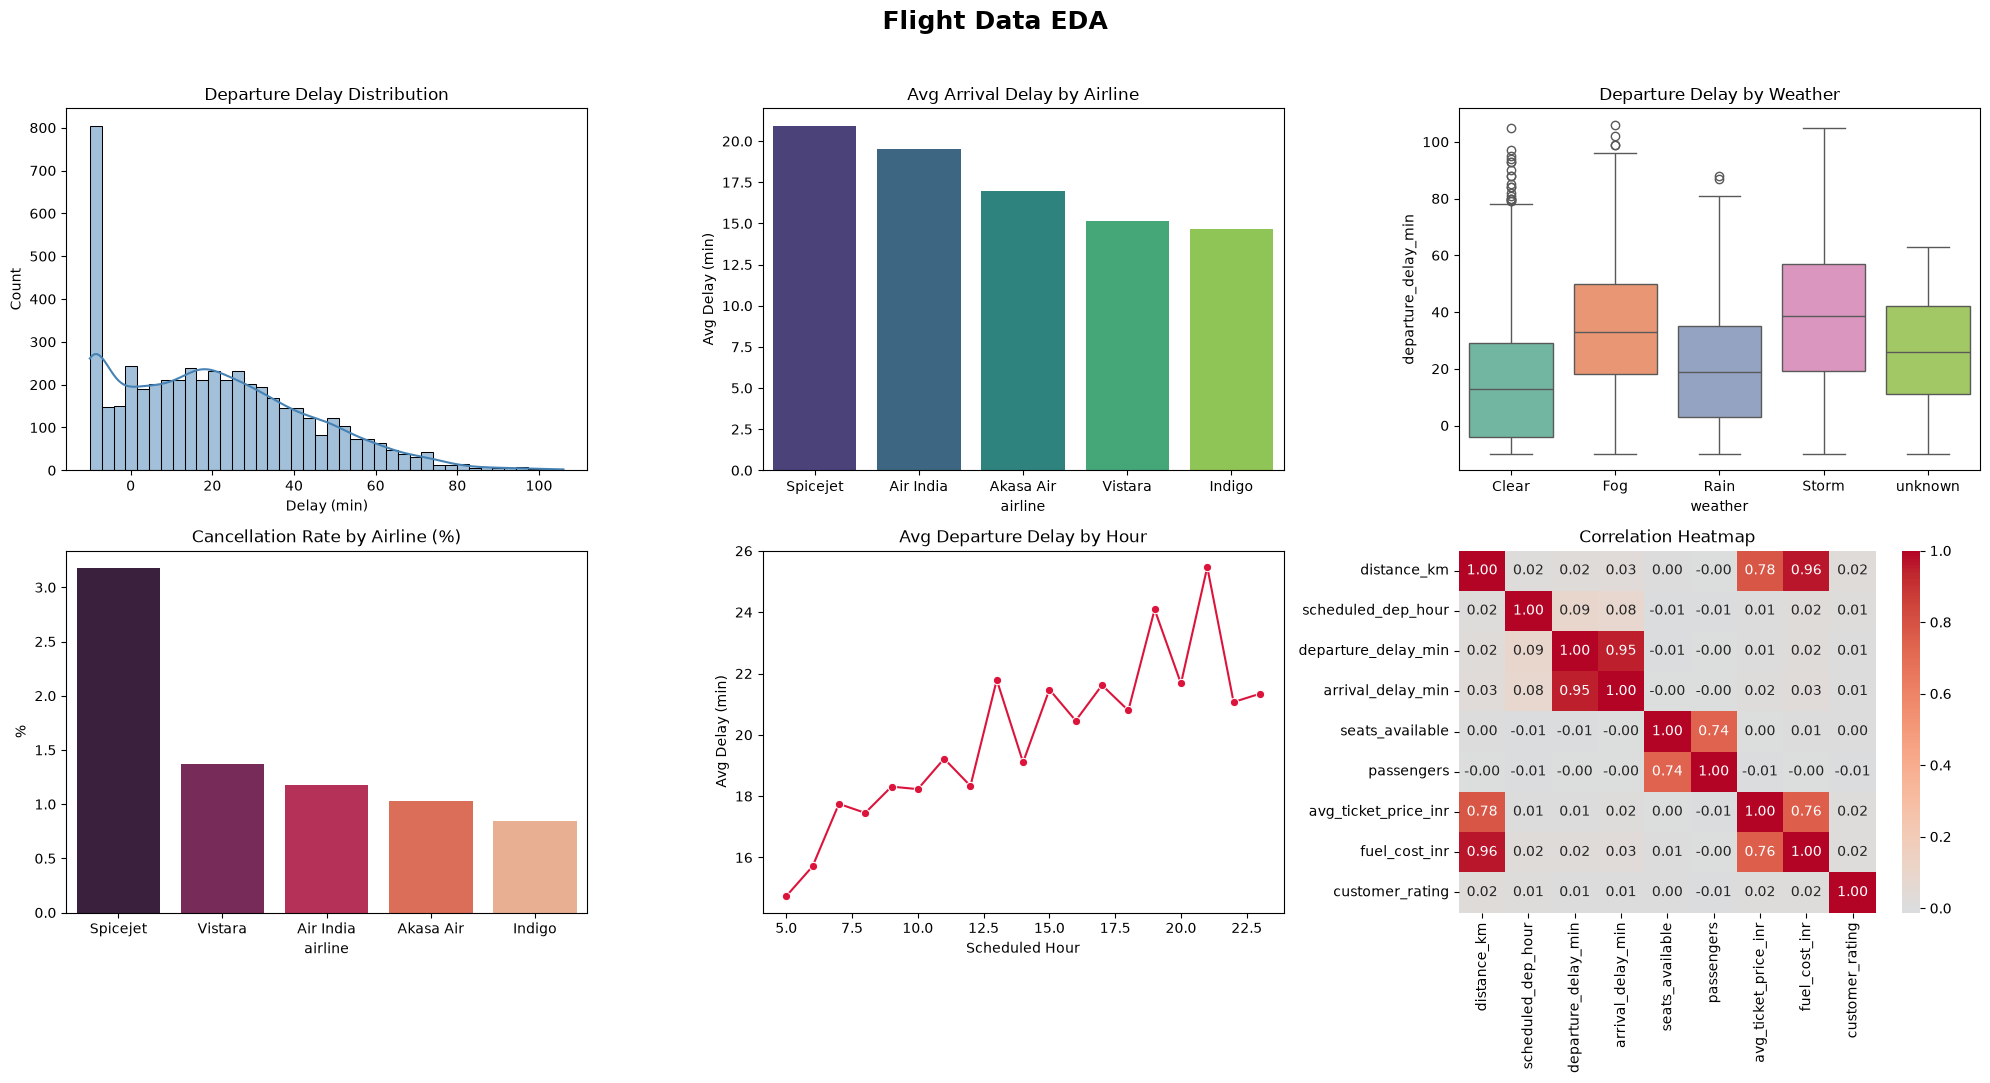

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Flight Data EDA", fontsize=18, fontweight="bold")

# 1. Departure delay distribution
sns.histplot(df["departure_delay_min"], bins=40, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Departure Delay Distribution")
axes[0, 0].set_xlabel("Delay (min)")

# 2. Average arrival delay by airline
airline_delay = df.groupby("airline")["arrival_delay_min"].mean().sort_values(ascending=False)
sns.barplot(x=airline_delay.index, y=airline_delay.values, palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("Avg Arrival Delay by Airline")
axes[0, 1].set_ylabel("Avg Delay (min)")

# 3. Departure delay by weather
sns.boxplot(data=df, x="weather", y="departure_delay_min", palette="Set2", ax=axes[0, 2])
axes[0, 2].set_title("Departure Delay by Weather")

# 4. Cancellation rate by airline (%)
cancel_rate = (df["cancelled"].eq("Yes").groupby(df["airline"]).mean() * 100).sort_values(ascending=False)
sns.barplot(x=cancel_rate.index, y=cancel_rate.values, palette="rocket", ax=axes[1, 0])
axes[1, 0].set_title("Cancellation Rate by Airline (%)")
axes[1, 0].set_ylabel("%")

# 5. Delay by scheduled departure hour
hourly = df.groupby("scheduled_dep_hour")["departure_delay_min"].mean()
sns.lineplot(x=hourly.index, y=hourly.values, marker="o", color="crimson", ax=axes[1, 1])
axes[1, 1].set_title("Avg Departure Delay by Hour")
axes[1, 1].set_xlabel("Scheduled Hour")
axes[1, 1].set_ylabel("Avg Delay (min)")

# 6. Correlation heatmap
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[1, 2])
axes[1, 2].set_title("Correlation Heatmap")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()